In [1]:
import numpy as np
import matplotlib.pyplot as plt
from main import NeuralNet

np.random.seed(42)


Создаём два облака точек, перемешиваем их и выделяем 75% для обучения

In [2]:
features = []
labels = []

for i in range(200):
    point = np.random.normal(-1, 0.6, 2)
    features.append(point)
    labels.append(0)

    point = np.random.normal(1, 0.6, 2)
    features.append(point)
    labels.append(1)

features = np.array(features)
labels = np.array(labels)

indexes = list(range(len(features)))
np.random.shuffle(indexes)
features = features[indexes]
labels = labels[indexes]

split = int(len(features) * 0.75)
train_features = features[:split]
train_labels = labels[:split]
test_features = features[split:]
test_labels = labels[split:]

print('Точек для обучения:', len(train_features))
print('Точек для проверки:', len(test_features))

Точек для обучения: 300
Точек для проверки: 100


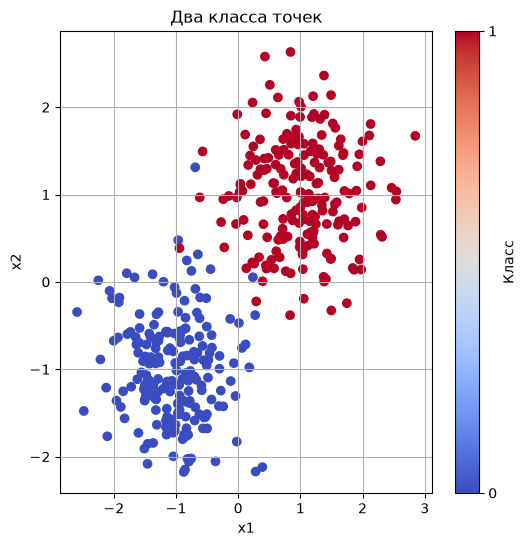

In [3]:
plt.figure(figsize=(6, 6))
plt.scatter(features[:, 0], features[:, 1], c=labels, cmap='coolwarm')
plt.colorbar(ticks=[0, 1], label='Класс')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Два класса точек')
plt.grid()
plt.show()



Два входа — координаты точки. Скрытый слой содержит 8 нейронов с ReLU

In [16]:
net = NeuralNet(2, 8, 'relu', 1, 'sigmoid')
loss = net.Loss()

epochs = 10
lr = 0.1
batch = 16

losses = []
accuracies = []


На каждой итерации вызываем `learn` на одну эпоху. После обновления весов отдельно считаем средний BCE на обучающих точках и accuracy на проверочных.

In [17]:
for epoch in range(epochs):
    net.learn(1, lr, batch, train_features, train_labels,
              loss.binary_cross_entropy, loss.GD)

    train_loss = 0
    for i in range(len(train_features)):
        y_pred = net.forward(train_features[i])
        train_loss = train_loss + loss.binary_cross_entropy(train_labels[i], y_pred)
    train_loss = train_loss / len(train_features)

    correct = 0
    for i in range(len(test_features)):
        y_pred = net.forward(test_features[i])
        if y_pred[0] >= 0.5:
            predicted_label = 1
        else:
            predicted_label = 0

        if predicted_label == test_labels[i]:
            correct = correct + 1

    accuracy = correct / len(test_features)
    losses.append(train_loss)
    accuracies.append(accuracy)

    if (epoch + 1) % 10 == 0:
        print(f'Эпоха {epoch + 1}: loss = {train_loss:.4f}, test accuracy = {accuracy:.2%}')

Эпоха 10: loss = 0.0435, test accuracy = 100.00%


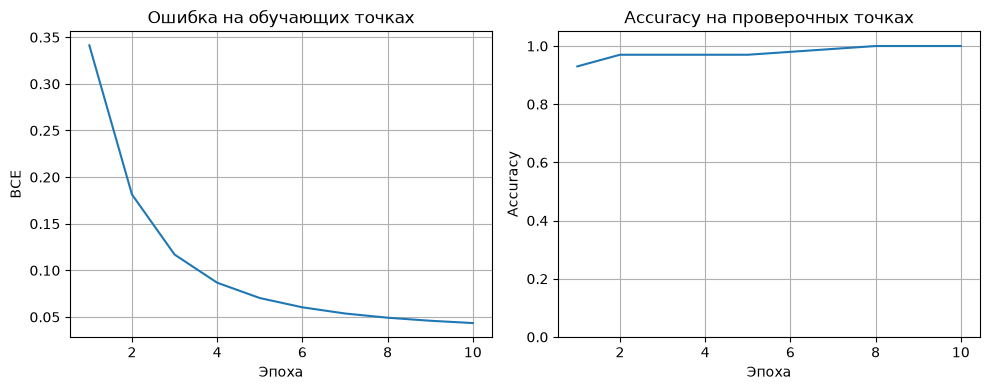

In [18]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), losses)
plt.xlabel('Эпоха')
plt.ylabel('BCE')
plt.title('Ошибка на обучающих точках')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), accuracies)
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.title('Accuracy на проверочных точках')
plt.grid()

plt.tight_layout()
plt.show()

Граница классов



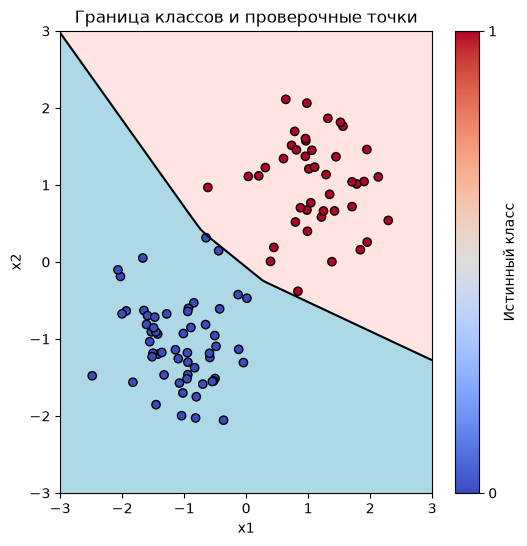

In [19]:
x1 = np.linspace(-3, 3, 80)
x2 = np.linspace(-3, 3, 80)
probabilities = np.zeros((len(x2), len(x1)))

for i in range(len(x2)):
    for j in range(len(x1)):
        point = [x1[j], x2[i]]
        y_pred = net.forward(point)
        probabilities[i, j] = y_pred[0]

plt.figure(figsize=(6, 6))
plt.contourf(x1, x2, probabilities, levels=[0, 0.5, 1],
             colors=['lightblue', 'mistyrose'])
plt.contour(x1, x2, probabilities, levels=[0.5], colors='black')
plt.scatter(test_features[:, 0], test_features[:, 1],
            c=test_labels, cmap='coolwarm', vmin=0, vmax=1, edgecolors='black')
plt.colorbar(ticks=[0, 1], label='Истинный класс')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Граница классов и проверочные точки')
plt.show()